### Electrical Grid Stability Margin Prediction Using Multiple Linear Regression

#### 1. Introduction
##### 1.1 Background
Electrical power systems are complex networks that consist of power generators, transmission lines, distribution networks, and consumers. These components work together to ensure a continuous and reliable supply of electricity.

Grid stability refers to the ability of an electrical power system to maintain a balanced and reliable operating condition when changes or disturbances occur in the network. These disturbances may result from changes in electricity demand, generator output, or system operating conditions.

Maintaining grid stability is important because unstable operating conditions can lead to voltage fluctuations, frequency variations, equipment damage, and even large-scale power outages.

With the increasing complexity of modern power systems, data-driven techniques such as Machine Learning and Statistical Modelling can help analyse grid behaviour and predict stability conditions.

##### 1.2 Problem Statement
This project focuses on predicting the stability margin of an electrical power grid using Multiple Linear Regression (MLR).

The stability of a grid depends on several interconnected parameters, including generator and consumer response times, power consumption, and price-elasticity coefficients.

The main objective is to develop a Multiple Linear Regression model that uses these parameters as independent variables to predict the continuous grid stability margin.

The project also investigates the relationship between different electrical and control-system parameters and grid stability, and evaluate model performance.

##### Research question:

`Can Multiple Linear Regression accurately predict the electrical grid stability margin using multiple electrical and control-system parameters?`

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#### 2. Dataset Overview

- Dataset: Electrical Grid Stability Simulated Data

In [2]:
dataset = pd.read_csv('UCI_Electrical_Grid_Stability_data.csv')
dataset.head(3)

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable


Exclude `p1` because it is derived from the other consumer power values. Also exclude `stabf` because it is a categorical (stable/unstable) label, not my regression target.

##### Understanding the variables:
- Tau (τ) parameters: Represent the response times of the producer and consumers. They describe how quickly different system components respond to changes in operating conditions.
- P parameters: Represent the nominal power values of the three consumers.
- G parameters: Represent the price-elasticity coefficients, which describe the sensitivity of production or consumption to price changes.

In [3]:
df = dataset.drop(columns=['p1', 'stabf']) # drop p1 and stabf columns
df.head(3)

,tau1,tau2,tau3,tau4,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471


Variable  ---	Engineering meaning	                   ---     Role

tau1	  -->  Producer reaction time	               -->     Input

tau2	  -->  Consumer 1 reaction time	               -->     Input

tau3	  -->  Consumer 2 reaction time	               -->     Input

tau4	  -->  Consumer 3 reaction time	               -->     Input

p2	      -->  Consumer 1 nominal power	               -->     Input

p3	      -->  Consumer 2 nominal power	               -->     Input

p4	      -->  Consumer 3 nominal power	               -->     Input

g1	      -->  Producer price-elasticity coefficient   -->     Input

g2	      -->  Consumer 1 price-elasticity coefficient -->     Input

g3	      -->  Consumer 2 price-elasticity coefficient -->     Input

g4	      -->  Consumer 3 price-elasticity coefficient -->     Input

stab	  -->  Grid stability margin indicator	       -->     Target

#### 3. Data Cleaning

Check duplicates, missing values and data types

In [4]:
df.isnull().sum() # check for missing values

tau1    0
tau2    0
tau3    0
tau4    0
p2      0
p3      0
p4      0
g1      0
g2      0
g3      0
g4      0
stab    0
dtype: int64

In [5]:
df.duplicated().sum() # check for duplicate rows

np.int64(0)

In [6]:
df.info() # check data types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p2      10000 non-null  float64
 5   p3      10000 non-null  float64
 6   p4      10000 non-null  float64
 7   g1      10000 non-null  float64
 8   g2      10000 non-null  float64
 9   g3      10000 non-null  float64
 10  g4      10000 non-null  float64
 11  stab    10000 non-null  float64
dtypes: float64(12)
memory usage: 937.6 KB


#### 4. Exploratory Data Analysis (EDA)	

Study distributions, correlations and outliers

In [9]:
df.describe() # get summary statistics for numerical columns

,tau1,tau2,tau3,tau4,p2,p3,p4,g1,g2,g3,g4,stab
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.250000,5.250001,5.250004,5.249997,-1.250000,-1.250000,-1.250000,0.525000,0.525000,0.525000,0.525000,0.015731
std,2.742548,2.742549,2.742549,2.742556,0.433035,0.433035,0.433035,0.274256,0.274255,0.274255,0.274255,0.036919
min,0.500793,0.500141,0.500788,0.500473,-1.999891,-1.999945,-1.999926,0.050009,0.050053,0.050054,0.050028,-0.080760
25%,2.874892,2.875140,2.875522,2.874950,-1.624901,-1.625025,-1.624960,0.287521,0.287552,0.287514,0.287494,-0.015557
50%,5.250004,5.249981,5.249979,5.249734,-1.249966,-1.249974,-1.250007,0.525009,0.525003,0.525015,0.525002,0.017142
75%,7.624690,7.624893,7.624948,7.624838,-0.874977,-0.875043,-0.875065,0.762435,0.762490,0.762440,0.762433,0.044878
max,9.999469,9.999837,9.999450,9.999443,-0.500108,-0.500072,-0.500025,0.999937,0.999944,0.999982,0.999930,0.109403


Distribution Analysis

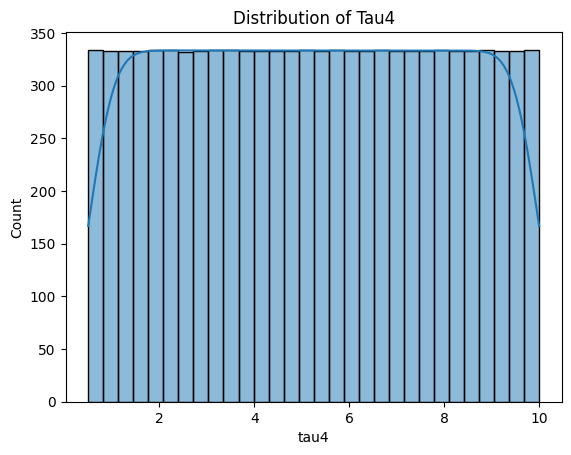

In [24]:
# Histogram for numerical column of interest (tau1)
# Distribution of tau1, tau2, tau3, tau4 are same, so we can just plot one of them
sns.histplot(data=df['tau4'], bins=30, kde=True)
plt.title('Distribution of Tau4')
plt.show()

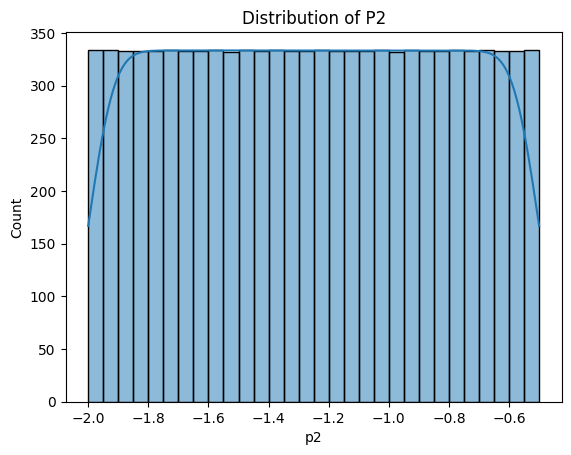

In [27]:
# Distribution of p2, p3, p4 are same, so we can just plot one of them
sns.histplot(data=df['p2'], bins=30, kde=True)
plt.title('Distribution of P2')
plt.show()

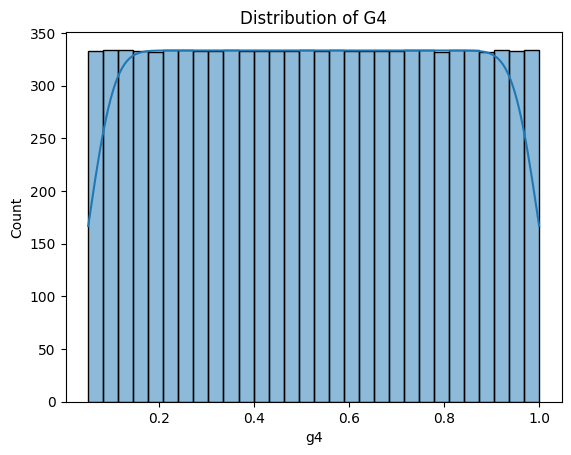

In [32]:
# Distribution of g1, g2, g3, g4 are same, so we can just plot one of them
sns.histplot(data=df['g4'], bins=30, kde=True)
plt.title('Distribution of G4')
plt.show()

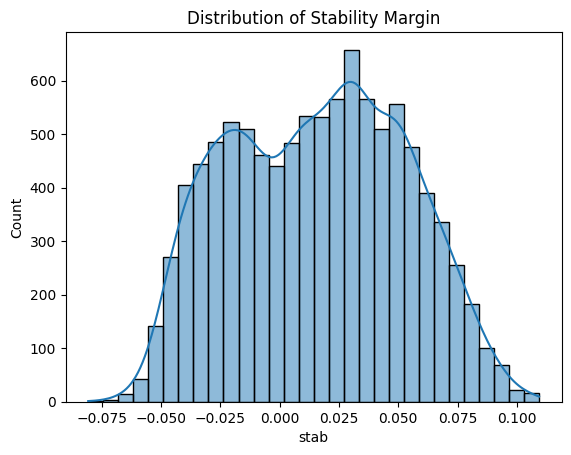

In [33]:
# Distribution of stable margin (target variable)
sns.histplot(data=df['stab'], bins=30, kde=True)
plt.title('Distribution of Stability Margin')
plt.show()

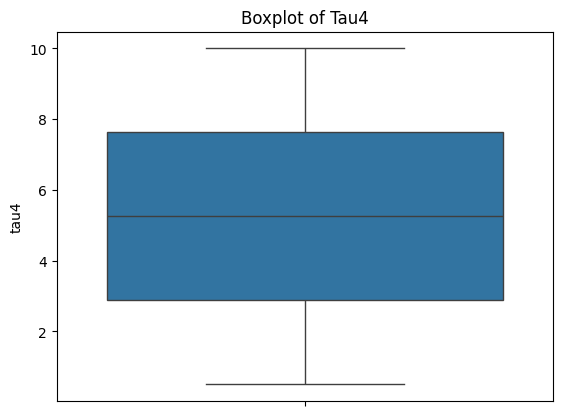

In [37]:
# Boxplot for numerical column of interest (tau1)
# Boxplot for tau1, tau2, tau3, tau4 are same, so we can just plot one of them
sns.boxplot(data=df['tau4'])
plt.title('Boxplot of Tau4')
plt.show()

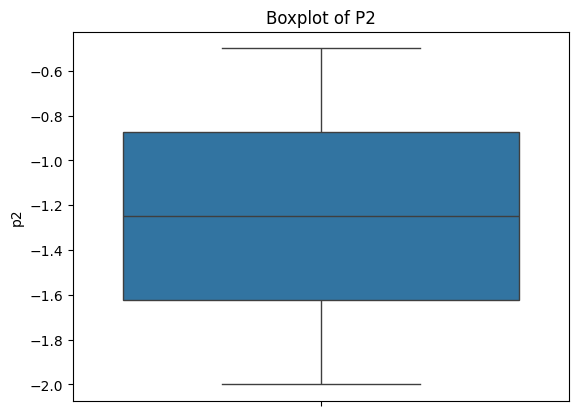

In [38]:
# Boxplot for numerical column of interest (p2)
# Boxplot for p2, p3, p4 are same, so we can just plot one of them
sns.boxplot(data=df['p2'])
plt.title('Boxplot of P2')
plt.show()

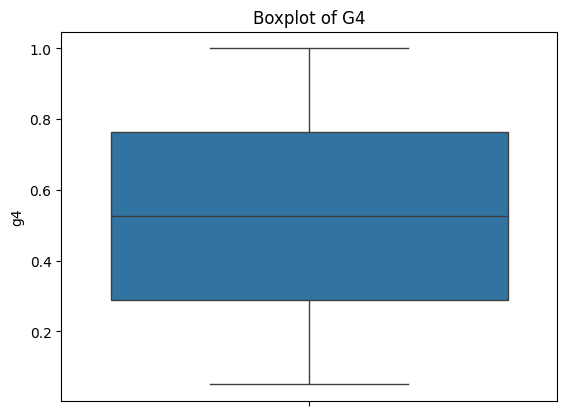

In [39]:
# Boxplot for numerical column of interest (g4)
# Boxplot for g1, g2, g3, g4 are same, so we can just plot one of them
sns.boxplot(data=df['g4'])
plt.title('Boxplot of G4')
plt.show()

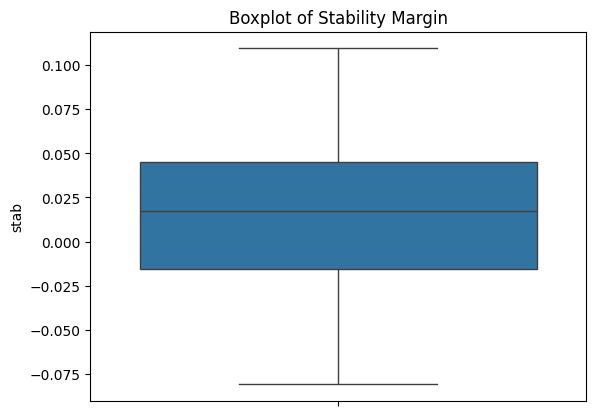

In [40]:
# Boxplot for numerical column of interest (Stability Margin)
sns.boxplot(data=df['stab'])
plt.title('Boxplot of Stability Margin')
plt.show()

In [88]:
# Correlation matrix
correlation_matrix = df.corr()
correlation_matrix

,tau1,tau2,tau3,tau4,p2,p3,p4,g1,g2,g3,g4,stab
tau1,1.000000,0.015586,-0.005970,-0.017265,-0.015485,-0.015924,-0.015807,0.010521,0.015350,-0.001279,0.005494,0.275761
tau2,0.015586,1.000000,0.014273,-0.001965,0.006573,0.007673,-0.005963,-0.001742,0.015383,0.016508,-0.011764,0.290975
tau3,-0.005970,0.014273,1.000000,0.004354,-0.003134,-0.008780,-0.017531,-0.011605,0.007671,0.014702,-0.011497,0.280700
tau4,-0.017265,-0.001965,0.004354,1.000000,0.010553,0.006169,-0.011211,-0.004149,0.008431,0.003260,-0.000491,0.278576
p2,-0.015485,0.006573,-0.003134,0.010553,1.000000,0.002388,-0.006844,0.015603,-0.018032,0.007555,0.019817,0.006255
p3,-0.015924,0.007673,-0.008780,0.006169,0.002388,1.000000,0.012953,-0.003219,-0.011575,-0.005897,-0.010485,-0.003321
p4,-0.015807,-0.005963,-0.017531,-0.011211,-0.006844,0.012953,1.000000,-0.013636,0.002850,-0.003515,0.017505,-0.020786
g1,0.010521,-0.001742,-0.011605,-0.004149,0.015603,-0.003219,-0.013636,1.000000,0.007559,-0.005836,0.012431,0.282774
g2,0.015350,0.015383,0.007671,0.008431,-0.018032,-0.011575,0.002850,0.007559,1.000000,-0.012809,-0.014909,0.293601
g3,-0.001279,0.016508,0.014702,0.003260,0.007555,-0.005897,-0.003515,-0.005836,-0.012809,1.000000,0.006900,0.308235


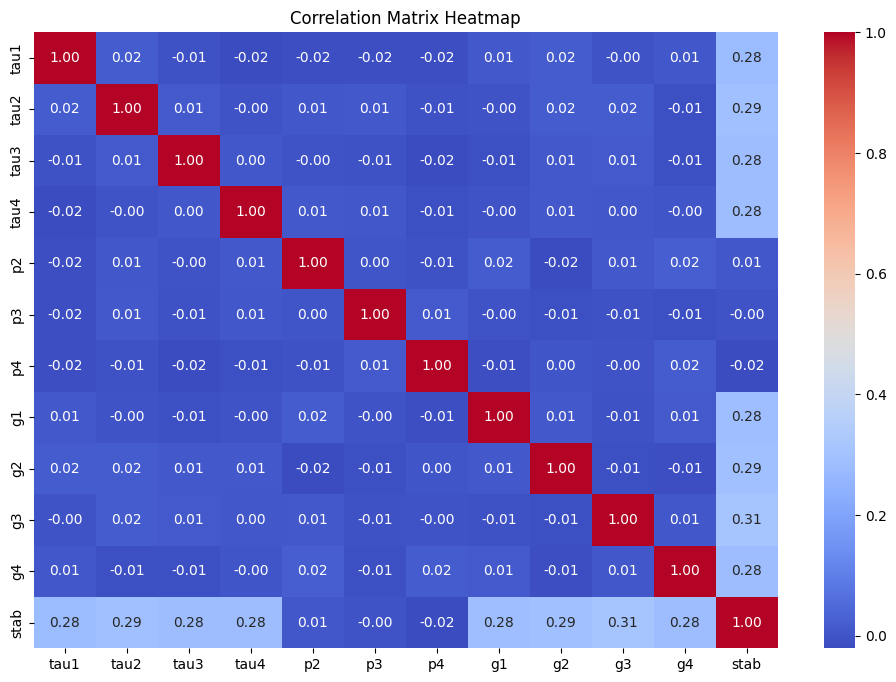

In [36]:
# visualize the correlation matrix using a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix Heatmap')
plt.show()

#### 5. Multiple Linear Regression Model Development

In [81]:
# Create independent and dependent variables
X = df.drop(columns=['stab']) # Independent variables
y = df['stab']  # Dependent variable

In [43]:
from sklearn.model_selection import train_test_split

In [72]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=32)

In [73]:
from sklearn.linear_model import LinearRegression

In [74]:
lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[0. ,0. ,0. ,...,0.04,0.04,0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['tau1','tau2','tau3',...,'g2','g3','g4']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.1429
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [75]:
lr.score(x_test, y_test)  # R-squared value on the test set

0.6685013263632985

In [76]:
y_pred = lr.predict(x_test)

#### 6. Model Evaluation

In [77]:
# MAE, MSE, RMSE and R-squared value
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared value: {r2}')

Mean Absolute Error (MAE): 0.01714509571973579
Mean Squared Error (MSE): 0.00046846908564385936
Root Mean Squared Error (RMSE): 0.02164414668319958
R-squared value: 0.6685013263632985


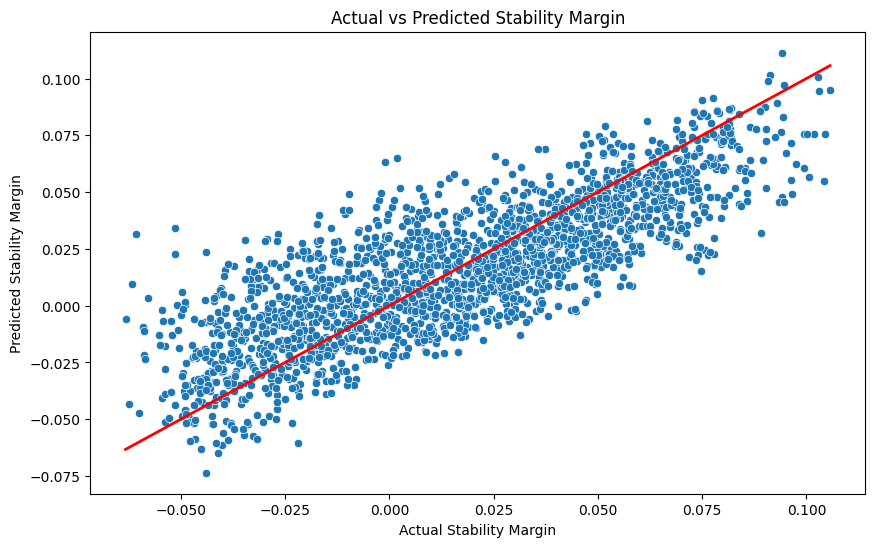

In [83]:
# Visualize the best fit line for the predicted vs actual values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2)  # Line of perfect prediction
plt.title('Actual vs Predicted Stability Margin')
plt.xlabel('Actual Stability Margin')
plt.ylabel('Predicted Stability Margin')
plt.show()

In [85]:
# Regression coefficient of the model
lr.coef_

array([ 0.00361887,  0.00373523,  0.00377779,  0.00380062,  0.00041357,
        0.00091277, -0.00052383,  0.03786651,  0.03906415,  0.03979133,
        0.03786885])

In [86]:
# intercept
lr.intercept_

np.float64(-0.1428655715832644)

The equation of Multiple Linear Regression becomes:

y = 0.00361887 * tau1 + 0.00373523 * tau2 + 0.00377779 * tau3 + 0.00380062 * tau4 + 0.00041357 * p2 + 0.00091277 * p3 - 0.00052383 * p4 + 0.03786651 * g1 + 0.03906415 * g2 + 0.03979133 * g3 + 0.03786885 * g4 - 0.1428655715832644